# Publication registration benchmark with PASTE2, MLP-MAE, and timing

Run this notebook from a fresh kernel, top to bottom. It loads the datasets, fits every method, evaluates the fixed cases, and exports the publication figures. **No other notebook, saved report, or existing fitted model is required.**

Both Allen MERFISH and BARseq use the same ten-method roster. Development cases remain separate from evaluation cases. This notebook uses its own fit-cache directory; clearing another experiment's caches cannot delete its fitted models.

Optional cache import copies only completed, configuration-matched fits. It never links model files, moves source caches, or consumes another notebook's variables. Leave the running evaluation alone; to reuse all of its completed fits, run this notebook after that evaluation finishes. Set `IMPORT_COMPLETED_FITS=False` for a completely fresh benchmark.

Dependencies: `requirements-registration.txt` plus `requirements-registration-controls.txt`. Dataset acquisition: `scripts/download_registration_allen.py` and `scripts/download_barseq_pilot.py`. Configure an absolute `SPATSPLAT_DATA_DIR` in `.env`.


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import torch
from dotenv import load_dotenv
from IPython.display import display
ROOT=Path.cwd().resolve()
while not ((ROOT/'pyproject.toml').exists() and (ROOT/'paper').is_dir()):
    if ROOT==ROOT.parent: raise RuntimeError('Repository root not found')
    ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
load_dotenv(ROOT/'.env')
from paper.dlpfc_splat_engine import ENGINE_DEFAULTS
from paper.dlpfc_registration import versions, pair_key
from paper.data_loaders.allen_registration import load_registration_sections
from paper.data_loaders.barseq_pilot import load_barseq_pilot
from paper.workflows.standardized_registration import (
    FAMILY_METHODS,source_signature,allen_cases,barseq_cases,run_cases)
from paper.workflows.standardized_rigid import (
    METHODS, DEFAULTS as RIGID_DEFAULTS, signature as rigid_signature, add_rigid, evaluate_cases)

SEED=1023
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
ALLEN_PAIRS=(('development',24,25),('evaluation',28,29),('evaluation',32,33))
BARSEQ_SECTIONS=(19,15,23,27)
ALLEN_MAXIMUM=3000
BARSEQ_MAXIMUM=8000
RUN={family:True for family in FAMILY_METHODS}
RUN_DIAGNOSTIC_FIGURES=False
RUN_SPLAT_RIGID=True
RIGID_SETTINGS=dict(RIGID_DEFAULTS, seed=SEED)
OPTIONS={
    'Geometry':dict(iterations=100),
    'PASTE':dict(alpha=.1,iterations=400,inner_iterations=1000000,gpu=False,seed=SEED),
    'CAST':dict(mark_epochs=400,affine_iterations=1500,ffd_iterations=800,gpu=False,
        seed=SEED,coordinate_scale=1000.,affine_step_multiplier=.1,ffd_step_size=5.,
        affine_diff_step=50.,ffd_diff_step=5.),
    'Splat':dict(ae_epochs=150,min_steps=1500,seed=SEED,device=DEVICE,
        engine_options={**ENGINE_DEFAULTS,
            'splat_config':dict(num_splats=512,latent_dim=32,hidden_dim=128,init_log_scale=-4.5,kernel_sharpness=.5),
            'section_splat_batch_size':512,'registration_query_count':2048,
            'nonaffine_grid_size':8,'nonaffine_displacement_weight':10.,'nonaffine_splat_match_weight':1.})}
SIGNATURE=source_signature(ROOT)
CONFIG=dict(seed=SEED,device=DEVICE,options=OPTIONS,versions=versions(),methods=METHODS,
    allen_pairs=ALLEN_PAIRS,barseq_sections=BARSEQ_SECTIONS,
    allen_maximum=ALLEN_MAXIMUM,barseq_maximum=BARSEQ_MAXIMUM,source_signature=SIGNATURE,
    rigid_settings=RIGID_SETTINGS,rigid_signature=rigid_signature(ROOT))
pd.options.display.float_format='{:.4g}'.format
display(pd.DataFrame([dict(family=f,outputs=', '.join(FAMILY_METHODS[f]),settings=json.dumps(OPTIONS[f])) for f in FAMILY_METHODS]))
print('One configuration per family for all tasks. Splat device:',DEVICE,'; CAST/PASTE: CPU')
print('RUN enables missing fits in this notebook\'s private cache.')
from paper.workflows.barseq_additional_controls import EXTRA_METHODS, score_additions
from paper.workflows.registration_timing import instrument
from paper.workflows.publication_controls import prepare_workspace, seed_completed_fits, runtime_figure

BASE_METHODS = METHODS
METHODS = (*BASE_METHODS, *EXTRA_METHODS)
IMPORT_COMPLETED_FITS = True
RUN_EXTRA = {method: True for method in EXTRA_METHODS}
EXTRA_OPTIONS = dict(
    paste2=dict(alpha=.1, iterations=1000, seed=SEED),
    mlp=dict(hidden_dim=128, epochs=300, min_steps=2000, batch_size=512,
             lr=1e-3, seed=SEED, device=DEVICE),
    rigid=dict(RIGID_SETTINGS))
CONFIG.update(methods=METHODS, extra_options=EXTRA_OPTIONS,
    extra_source=hashlib.sha256((ROOT/'paper/workflows/barseq_additional_controls.py').read_bytes()).hexdigest(),
    publication_sources={name: hashlib.sha256((ROOT/'paper/workflows'/name).read_bytes()).hexdigest()
        for name in ('publication_controls.py','registration_timing.py','standardized_publication.py')})
print('Ten methods on both datasets:', METHODS)


,family,outputs,settings
0,Geometry,Geometry rigid ICP,"{""iterations"": 100}"
1,PASTE,PASTE rigid,"{""alpha"": 0.1, ""iterations"": 400, ""inner_itera..."
2,CAST,"CAST affine, CAST non-affine","{""mark_epochs"": 400, ""affine_iterations"": 1500..."
3,Splat,"Splat affine, Splat non-affine","{""ae_epochs"": 150, ""min_steps"": 1500, ""seed"": ..."


One configuration per family for all tasks. Splat device: cuda ; CAST/PASTE: CPU
RUN enables missing fits in this notebook's private cache.
Ten methods on both datasets: ('Unregistered', 'Geometry rigid ICP', 'PASTE rigid', 'CAST affine', 'CAST non-affine', 'Splat rigid', 'Splat affine', 'Splat non-affine', 'PASTE2 rigid', 'MLP-MAE rigid')


## Dependencies and data

The checks below do not download data or train models. The PASTE2 adapter is pinned to version 1.0.1. Its documented stability retries use only training data, not registration accuracy or known crop overlap.


In [2]:
import importlib, importlib.metadata, os, platform

missing = []
for module in ('CAST', 'dgl', 'paste', 'ot', 'abc_atlas_access', 'anndata', 'matplotlib', 'paste2.PASTE2', 'paste2.model_selection'):
    try:
        importlib.import_module(module)
    except Exception as exc:
        missing.append(f'{module}: {type(exc).__name__}: {exc}')
if missing:
    raise RuntimeError('Registration dependencies failed to import. See requirements-registration.txt:\n' + '\n'.join(missing))
base = os.getenv('SPATSPLAT_DATA_DIR')
if not base or base == '/path/to/spatsplat/data':
    raise RuntimeError('Copy .env.example to .env and set an absolute SPATSPLAT_DATA_DIR.')
DATA_ROOT = Path(base).expanduser()
ATLAS_ROOT = Path(os.getenv('SPATSPLAT_ABC_ATLAS_DIR', str(DATA_ROOT/'raw/abc_atlas'))).expanduser()
if not DATA_ROOT.is_absolute() or not ATLAS_ROOT.is_absolute():
    raise ValueError('Use absolute data/cache paths to avoid working-directory-dependent results.')
os.environ['SPATSPLAT_DATA_DIR'] = str(DATA_ROOT)
os.environ['SPATSPLAT_ABC_ATLAS_DIR'] = str(ATLAS_ROOT)
from paper.data_loaders.barseq_pilot import FILENAME
if not (DATA_ROOT/'raw/barseq_pilot'/FILENAME).is_file():
    raise FileNotFoundError('Run python scripts/download_barseq_pilot.py before continuing.')
if not ATLAS_ROOT.exists():
    raise FileNotFoundError('Run python scripts/download_registration_allen.py before continuing.')
COMMIT_MANIFEST = ROOT/'docs/registration_publication_controls_files.txt'
required_files = [line.strip() for line in COMMIT_MANIFEST.read_text().splitlines()
                  if line.strip() and not line.startswith('#')]
absent = [name for name in required_files if not (ROOT/name).is_file()]
if absent:
    raise FileNotFoundError('Incomplete repository checkout: ' + ', '.join(absent))
print('Data directory:', DATA_ROOT)
print('Allen cache:', ATLAS_ROOT)
print('Splat device:', DEVICE, '; CAST and PASTE: CPU')

if importlib.metadata.version('paste2') != '1.0.1':
    raise RuntimeError('Install paste2==1.0.1; see requirements-registration-controls.txt')
CONFIG['paste2_version'] = importlib.metadata.version('paste2')
CONFIG['paste2_direct_url'] = importlib.metadata.distribution('paste2').read_text('direct_url.json')


Data directory: /data/spatsplat-registration/data
Allen cache: /data/spatsplat-registration/data/raw/abc_atlas
Splat device: cuda ; CAST and PASTE: CPU


## Fixed datasets and cases

Allen: natural adjacent sections and combined rotation plus smooth deformation, with pair 24/25 for development and pairs 28/29 and 32/33 for evaluation.

BARseq: section 19 for development; sections 15, 23, and 27 for evaluation. Disjoint measurement pools and fixed held-out shared-region targets are retained. Shared-parent fractions are 100%, 60%, and 20%. The partial-coverage cases have three crop directions; full coverage has one case per section.

Allen remains a transductive registration task; BARseq uses training-only fits and held-out scoring. Do not pool these evaluation designs.


In [3]:
allen = load_registration_sections(sorted({s for _,a,b in ALLEN_PAIRS for s in (a,b)}),
    maximum=ALLEN_MAXIMUM, seed=SEED)
for _, a, b in ALLEN_PAIRS:
    if not np.isclose(allen['blocks'][b]['z']-allen['blocks'][a]['z'], .2):
        raise ValueError(f'Unexpected Allen slice gap {a}/{b}')
cases = allen_cases(allen, ALLEN_PAIRS)
barseq = load_barseq_pilot()
cases += barseq_cases(barseq, BARSEQ_SECTIONS, maximum=BARSEQ_MAXIMUM, seed=SEED)
del allen, barseq
inventory = pd.DataFrame([dict(case=c['name'], dataset=c['dataset'], task=c['task'],
    role=c['role'], section=c['section'], direction=c['direction'],
    shared_fraction=c['shared_fraction'], retained_fraction=c['retained_fraction'],
    reference_fit=len(c['pair']['xy'][0]), query_fit=len(c['pair']['xy'][1]),
    reference_evaluated=len(c['reference_eval']), query_evaluated=len(c['query_eval']),
    evaluation_design=c['evaluation_design']) for c in cases])
ID, FIT_ROOT, OUTPUT, FIGURES = prepare_workspace(ROOT, CONFIG, cases)
inventory.to_csv(OUTPUT/'case_inventory.csv', index=False)
(OUTPUT/'environment.json').write_text(json.dumps(dict(
    python=platform.python_version(), platform=platform.platform(), versions=versions(),
    data_root=str(DATA_ROOT), atlas_root=str(ATLAS_ROOT),
    device=DEVICE, paste2_version=CONFIG['paste2_version']), indent=2))
display(inventory)
print('Expected results:', len(cases)*len(METHODS))
print('Private fit root:', FIT_ROOT)
print('Reports:', OUTPUT)
print('Figures:', FIGURES)


,case,dataset,task,role,section,direction,shared_fraction,retained_fraction,reference_fit,query_fit,reference_evaluated,query_evaluated,evaluation_design
0,allen_24_25_natural,Allen,natural,development,24,0,1,1,3000,3000,3000,3000,transductive; annotations and true transform w...
1,allen_24_25_combined_distortion,Allen,combined_distortion,development,24,0,1,1,3000,3000,3000,3000,transductive; annotations and true transform w...
2,allen_28_29_natural,Allen,natural,evaluation,28,0,1,1,3000,3000,3000,3000,transductive; annotations and true transform w...
3,allen_28_29_combined_distortion,Allen,combined_distortion,evaluation,28,0,1,1,3000,3000,3000,3000,transductive; annotations and true transform w...
4,allen_32_33_natural,Allen,natural,evaluation,32,0,1,1,3000,3000,3000,3000,transductive; annotations and true transform w...
5,allen_32_33_combined_distortion,Allen,combined_distortion,evaluation,32,0,1,1,3000,3000,3000,3000,transductive; annotations and true transform w...
6,barseq_19_keep_1_direction_0,BARseq,unequal_coverage,initial,19,0,1,1,2400,2400,800,800,held-out disjoint acquisitions; train only; re...
7,barseq_19_keep_0.8_direction_0,BARseq,unequal_coverage,initial,19,0,0.6,0.8,1930,1913,490,463,held-out disjoint acquisitions; train only; re...
8,barseq_19_keep_0.8_direction_60,BARseq,unequal_coverage,initial,19,60,0.6,0.8,1929,1946,471,490,held-out disjoint acquisitions; train only; re...
9,barseq_19_keep_0.8_direction_120,BARseq,unequal_coverage,initial,19,120,0.6,0.8,1947,1963,448,473,held-out disjoint acquisitions; train only; re...


Expected results: 340
Private fit root: /home/javeda/Documents/Research/spatsplat-registration/notebooks/checkpoints/registration_publication_controls/5b2016112ab99603ff0c/private_fits
Reports: /home/javeda/Documents/Research/spatsplat-registration/notebooks/checkpoints/registration_publication_controls/5b2016112ab99603ff0c/reports
Figures: /home/javeda/Documents/Research/spatsplat-registration/figures/registration_publication_controls/5b2016112ab99603ff0c


## Optional import of completed fits

This is a speed optimization, not a prerequisite. Matching uses training data, model configuration, package versions, and implementation fingerprints. Partial fits from a running experiment are skipped. Imported models are independent file copies. Existing scores are not imported: this notebook computes its own evaluation.

Recorded timings are imported only for matching protocols and copied fit stages; missing historical timings remain unknown. The import log records every source and destination.


In [4]:
if IMPORT_COMPLETED_FITS:
    imported = seed_completed_fits(ROOT, FIT_ROOT, OUTPUT, cases,
        OPTIONS, EXTRA_OPTIONS, RIGID_SETTINGS, SIGNATURE)
    display(imported.groupby('stages')[['copied','available']].sum())
else:
    print('No external fit caches will be imported. Existing private fits may still be reused.')


,copied,available
stages,,
CAST family,34,34
Geometry family,34,34
MLP fields; MLP rigid pose,34,34
PASTE family,34,34
PASTE2 full pipeline,34,34
Splat family,34,34
Splat rigid pose,34,34


## Fit the common ten-method roster

All fitting writes to the private artifact root. PASTE2 estimates transported mass from training expression and spatial geometry. MLP-MAE fits raw-count MAE fields and then uses the same expression-only rigid pose optimizer as Splat rigid. The splat field objective remains unchanged, so this is not a representation-only ablation.

Field diagnostics are post-fit observations, never a criterion for selecting a pose. Failed methods remain explicit; the publication figure requires the complete matrix.


In [5]:
run_cases_private, add_rigid_private, run_additions_private, timing_log = instrument(
    OUTPUT, source_root=ROOT)
fitted, status = run_cases_private(cases, OPTIONS, FIT_ROOT, OUTPUT, RUN, SIGNATURE)
fitted, status = add_rigid_private(cases, fitted, status, OPTIONS['Splat'], FIT_ROOT,
    OUTPUT, RIGID_SETTINGS, run=RUN_SPLAT_RIGID)
status.to_csv(OUTPUT/'base_fit_status.csv', index=False)
fitted, additional_status, field_diagnostics = run_additions_private(
    cases, fitted, status, OPTIONS, EXTRA_OPTIONS, FIT_ROOT, OUTPUT, SIGNATURE, RUN_EXTRA)
display(status.groupby(['dataset','family','status']).size().rename('cases'))
display(additional_status.groupby(['method','status']).size().rename('cases'))


Loaded Geometry: d86b1cee2c8bb8927c92
Loaded PASTE: aceb932ca6ec91dc50c4
Loaded CAST: 1a08d43b58a235f58f49


/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Loaded Splat: f1583e8b3572e8959a65
Loaded Geometry: 81b79ac438530eb2ffae
Loaded PASTE: 52cb0fdf42bdc4474cb3
Loaded CAST: 640a8acbaac01eb2a27a
Loaded Splat: ba0d7279fe4a876459fd
Loaded Geometry: b930505ca6ae78b2a92c
Loaded PASTE: 294fc30977343f9072ba
Loaded CAST: 2bdbc7a0ecc4c4584ce8
Loaded Splat: 3592ff5651a0d9022231
Loaded Geometry: 76f9e1eb0f23b2fb4710
Loaded PASTE: 001e921deda0bb6268fa
Loaded CAST: e4e1816bf0c64f45cc9e
Loaded Splat: 2446884a41033f43ab20
Loaded Geometry: a5aff1d5add4049867d5
Loaded PASTE: c6c452bfd9a4bb713e82
Loaded CAST: 93a7fc7462c722cc9d93
Loaded Splat: cda70145edb904fa1964
Loaded Geometry: 1ae5bb0f3740a302bd69
Loaded PASTE: e94bc9c83764a07eaa1b
Loaded CAST: 1008aac308399cafe5f7
Loaded Splat: e35c61e23f2b457fd722
Loaded Geometry: 73abae456dc3594dd67c
Loaded PASTE: 4e94720410a6484e2027
Loaded CAST: bc70b75c16b1162cfeec
Loaded Splat: 4766852e4851206069e1
Loaded Geometry: 9acc18a86950d2468e32
Loaded PASTE: b8402d4567205755d2ac
Loaded CAST: 41b341e93f95568f0735
Loaded

dataset  family       status   
Allen    CAST         available     6
         Geometry     available     6
         PASTE        available     6
         Splat        available     6
         Splat rigid  available     6
BARseq   CAST         available    28
         Geometry     available    28
         PASTE        available    28
         Splat        available    28
         Splat rigid  available    28
Name: cases, dtype: int64

method         status   
MLP-MAE rigid  available    34
PASTE2 rigid   available    34
Name: cases, dtype: int64

## Evaluate every method consistently

Natural Allen alignment uses CCF division agreement. Controlled Allen recovery and BARseq unequal coverage use positional accuracy and error in reference-neighbor spacings. Coverage-weighted observed-expression cosine is reported separately. Annotations, true transforms, and held-out BARseq targets are not used for model fitting or overlap selection.

Development and evaluation are displayed separately. Variability across crop directions is not biological replication.


In [6]:
base_output = OUTPUT/'base_evaluation'; base_output.mkdir(exist_ok=True)
base_scores, base_availability = evaluate_cases(
    cases, fitted, base_output, permutations=99, seed=SEED)
extra_scores, extra_availability = score_additions(
    cases, fitted, OUTPUT/'additional_evaluation', permutations=99, seed=SEED)
scores = pd.concat([base_scores, extra_scores], ignore_index=True)
availability = pd.concat([base_availability, extra_availability], ignore_index=True)
scores.to_csv(OUTPUT/'scores.csv', index=False)
availability.to_csv(OUTPUT/'method_availability.csv', index=False)
complete = bool(len(availability)==len(cases)*len(METHODS) and availability.available.all())
(OUTPUT/'completion.json').write_text(json.dumps(dict(complete=complete,
    expected=len(cases)*len(METHODS), available=int(availability.available.sum())), indent=2))
display(availability.groupby('method').available.agg(['sum','count']))
metric_columns = ['ccf_division_agreement','positional_accuracy',
                  'median_error_neighbor_spacings','coverage_weighted_cosine']
for role in ('development','initial','evaluation'):
    selected = scores[scores.role==role]
    if not selected.empty:
        print('Role:', role)
        display(selected.groupby(['dataset','task','shared_fraction','method'])[metric_columns].mean())
if not complete:
    display(status[status.status!='available'])
    display(additional_status[additional_status.status!='available'])
    print('Resolve missing fits and rerun fitting/scoring before making the main figure.')


,sum,count
method,,
CAST affine,34,34
CAST non-affine,34,34
Geometry rigid ICP,34,34
MLP-MAE rigid,34,34
PASTE rigid,34,34
PASTE2 rigid,34,34
Splat affine,34,34
Splat non-affine,34,34
Splat rigid,34,34


Role: development


ccf_division_agreement  \
dataset task                shared_fraction method                                       
Allen   combined_distortion 1               CAST affine                            NaN   
                                            CAST non-affine                        NaN   
                                            Geometry rigid ICP                     NaN   
                                            MLP-MAE rigid                          NaN   
                                            PASTE rigid                            NaN   
                                            PASTE2 rigid                           NaN   
                                            Splat affine                           NaN   
                                            Splat non-affine                       NaN   
                                            Splat rigid                            NaN   
                                            Unregistered                           NaN   
        natural             1               CAST affine                          0.793   
                                            CAST non-affine                     0.8204   
                                            Geometry rigid ICP                   0.786   
                                            MLP-MAE rigid                       0.7527   
                                            PASTE rigid                         0.7762   
                                            PASTE2 rigid                        0.7957   
                                            Splat affine                         0.797   
                                            Splat non-affine                    0.7995   
                                            Splat rigid                         0.7973   
                                            Unregistered                        0.8043   

                                                                positional_accuracy  \
dataset task                shared_fraction method                                    
Allen   combined_distortion 1               CAST affine                     0.05629   
                                            CAST non-affine                  0.6252   
                                            Geometry rigid ICP               0.1501   
                                            MLP-MAE rigid                   0.03539   
                                            PASTE rigid                      0.2181   
                                            PASTE2 rigid                     0.2806   
                                            Splat affine                     0.5287   
                                            Splat non-affine                 0.4934   
                                            Splat rigid                      0.2147   
                                            Unregistered                    0.03541   
        natural             1               CAST affine                         NaN   
                                            CAST non-affine                     NaN   
                                            Geometry rigid ICP                  NaN   
                                            MLP-MAE rigid                       NaN   
                                            PASTE rigid                         NaN   
                                            PASTE2 rigid                        NaN   
                                            Splat affine                        NaN   
                                            Splat non-affine                    NaN   
                                            Splat rigid                         NaN   
                                            Unregistered                        NaN   

                                                                median_error_neighbor_spacings  \
dataset task                shared_fraction method                    

Role: initial


ccf_division_agreement  \
dataset task             shared_fraction method                                       
BARseq  unequal_coverage 0.2             CAST affine                            NaN   
                                         CAST non-affine                        NaN   
                                         Geometry rigid ICP                     NaN   
                                         MLP-MAE rigid                          NaN   
                                         PASTE rigid                            NaN   
                                         PASTE2 rigid                           NaN   
                                         Splat affine                           NaN   
                                         Splat non-affine                       NaN   
                                         Splat rigid                            NaN   
                                         Unregistered                           NaN   
                         0.6             CAST affine                            NaN   
                                         CAST non-affine                        NaN   
                                         Geometry rigid ICP                     NaN   
                                         MLP-MAE rigid                          NaN   
                                         PASTE rigid                            NaN   
                                         PASTE2 rigid                           NaN   
                                         Splat affine                           NaN   
                                         Splat non-affine                       NaN   
                                         Splat rigid                            NaN   
                                         Unregistered                           NaN   
                         1               CAST affine                            NaN   
                                         CAST non-affine                        NaN   
                                         Geometry rigid ICP                     NaN   
                                         MLP-MAE rigid                          NaN   
                                         PASTE rigid                            NaN   
                                         PASTE2 rigid                           NaN   
                                         Splat affine                           NaN   
                                         Splat non-affine                       NaN   
                                         Splat rigid                            NaN   
                                         Unregistered                           NaN   

                                                             positional_accuracy  \
dataset task             shared_fraction method                                    
BARseq  unequal_coverage 0.2             CAST affine                     0.04091   
                                         CAST non-affine                  0.1141   
                                         Geometry rigid ICP              0.04897   
                                         MLP-MAE rigid                   0.02243   
                                         PASTE rigid                     0.04784   
                                         PASTE2 rigid                    0.07027   
                                         Splat affine                    0.06736   
                                         Splat non-affine                0.07503   
                                         Splat rigid                      0.1077   
                                         Unregistered                    0.03755   
                         0.6             CAST affine                      0.0418   
                                         CAST non-affine                  0.1584   
                                         Geometry rigid ICP              0.07369   
                

Role: evaluation


ccf_division_agreement  \
dataset task                shared_fraction method                                       
Allen   combined_distortion 1               CAST affine                            NaN   
                                            CAST non-affine                        NaN   
                                            Geometry rigid ICP                     NaN   
                                            MLP-MAE rigid                          NaN   
                                            PASTE rigid                            NaN   
                                            PASTE2 rigid                           NaN   
                                            Splat affine                           NaN   
                                            Splat non-affine                       NaN   
                                            Splat rigid                            NaN   
                                            Unregistered                           NaN   
        natural             1               CAST affine                         0.7221   
                                            CAST non-affine                     0.7245   
                                            Geometry rigid ICP                  0.7188   
                                            MLP-MAE rigid                       0.6989   
                                            PASTE rigid                         0.7146   
                                            PASTE2 rigid                        0.5184   
                                            Splat affine                        0.7216   
                                            Splat non-affine                    0.7225   
                                            Splat rigid                         0.7193   
                                            Unregistered                        0.7189   
BARseq  unequal_coverage    0.2             CAST affine                            NaN   
                                            CAST non-affine                        NaN   
                                            Geometry rigid ICP                     NaN   
                                            MLP-MAE rigid                          NaN   
                                            PASTE rigid                            NaN   
                                            PASTE2 rigid                           NaN   
                                            Splat affine                           NaN   
                                            Splat non-affine                       NaN   
                                            Splat rigid                            NaN   
                                            Unregistered                           NaN   
                            0.6             CAST affine                            NaN   
                                            CAST non-affine                        NaN   
                                            Geometry rigid ICP                     NaN   
                                            MLP-MAE rigid                          NaN   
                                            PASTE rigid                            NaN   
                                            PASTE2 rigid                           NaN   
                                            Splat affine                           NaN   
                                            Splat non-affine                       NaN   
                                            Splat rigid                            NaN   
                                            Unregistered                           NaN   
                            1               CAST affine                            NaN   
                                            CAST non-affine                        NaN   
                                            Geometry rigid ICP                     NaN   
              

## Export plotting data

Run this cell once after scoring, or run just this cell now if `cases`, `METHODS`, and `OUTPUT` are still in memory. It reads saved scores and maps; it does not fit, register, or evaluate anything. It resolves and saves region labels once so future plotting needs no raw datasets or atlas access.

After export, use `registration_publication_plots-allen_barseq.ipynb` for all figure edits. Every export creates a new portable bundle without overwriting earlier exports. Incomplete results can be exported for inspection, but the main comparison still requires a complete matrix.


In [7]:
from paper.workflows.registration_plot_data import export_plot_bundle

# To export an older run, set this to its existing reports directory.
PLOT_REPORT = OUTPUT
PLOT_BUNDLE = export_plot_bundle(PLOT_REPORT, cases, METHODS)
print('Plotting data saved to:', PLOT_BUNDLE)
print('Open the plotting-only notebook; no experiment rerun is required.')


Plotting data saved to: /home/javeda/Documents/Research/spatsplat-registration/notebooks/checkpoints/registration_publication_controls/5b2016112ab99603ff0c/reports/plot_data/20261101T214518078609Z
Open the plotting-only notebook; no experiment rerun is required.


## Publication figure

**A:** natural Allen 29-to-28 inferred measurement correspondences for Splat rigid.
**B:** CCF division agreement on the two evaluation pairs.
**C:** combined-distortion recovery correspondences for Splat rigid.
**D:** controlled positional accuracy on both evaluation sections.
**E/F:** BARseq unequal coverage before and after Splat rigid registration.
**G:** positional accuracy across three shared-parent fractions and the three evaluation sections.

The method roster is identical in every quantitative panel. Colors identify methods; section markers and hatches identify cases. Main panels exclude coverage-weighted cosine to keep the figure compact. Spatial links are inferred correspondences, not ground-truth measurement pairs.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


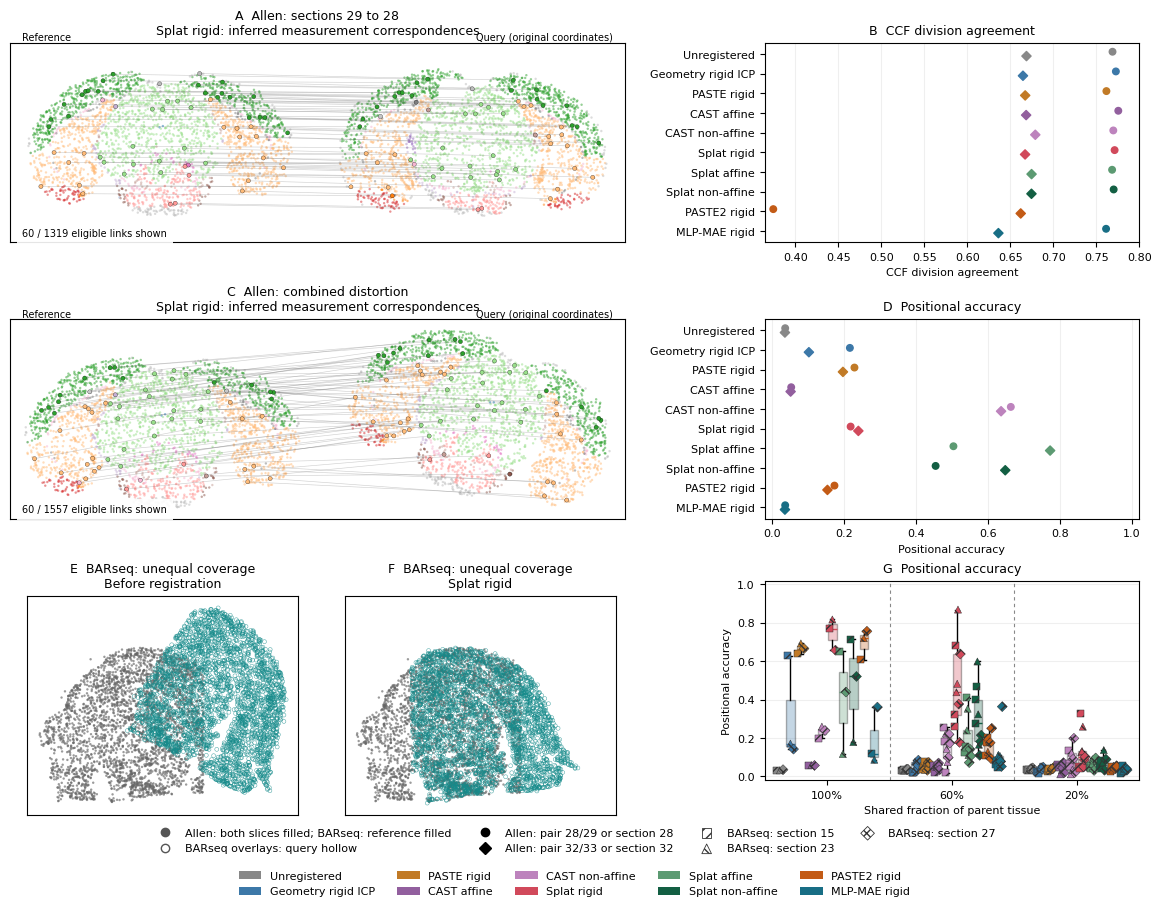

In [8]:
import matplotlib.pyplot as plt
from paper.workflows.standardized_publication import publication_figure

if not complete:
    display(availability.loc[~availability.available])
    display(additional_status.loc[additional_status.status != 'available'])
    raise RuntimeError('Missing fits are listed above. Resume fitting and rerun evaluation before exporting the publication figure.')
publication = publication_figure(cases, fitted, scores, methods=METHODS,
    example_method='Splat rigid', include_cosine=False, measurement_links=True, maximum_links=60)
for extension in ('pdf','png'):
    publication.savefig(FIGURES/f'registration_ten_methods.{extension}', dpi=300, bbox_inches='tight')
plt.show()
plt.close(publication)


## Runtime tables and separate figure

Only completed **fresh** work enters the fit-time summaries. Cache loads, resumed work, failures, and unknown historical times remain visible in the event log. CUDA is synchronized. Evaluation, field diagnostics, and publication plotting are excluded.

These are **workload-stage timings**, not hardware-matched method speed rankings:
- PASTE2 includes expression preprocessing, numerical retries, overlap selection, and alignment.
- Splat family includes shared field preparation plus affine and non-affine fitting; Splat rigid pose is an additional stage.
- CAST family includes its shared embedding and both affine variants.
- MLP field fitting and rigid pose optimization are separate.
- PASTE/PASTE2 and CAST use CPU in this protocol; splats/MLP use the configured device.

The runtime figure shows evaluation cases only, with separate datasets. The table retains development cases. Missing timing is not zero. Imported logs retain their original machine metadata; do not combine different machines as an algorithmic speed estimate.


count  \
dataset task                role        shared_fraction stage                         
Allen   combined_distortion development 1               CAST family               0   
                                                        Geometry family           0   
                                                        MLP fields                1   
                                                        MLP rigid pose            1   
                                                        PASTE family              0   
...                                                                             ...   
BARseq  unequal_coverage    initial     1               MLP rigid pose            1   
                                                        PASTE family              1   
                                                        PASTE2 full pipeline      1   
                                                        Splat family              1   
                                                        Splat rigid pose          1   

                                                                              median  \
dataset task                role        shared_fraction stage                          
Allen   combined_distortion development 1               CAST family              NaN   
                                                        Geometry family          NaN   
                                                        MLP fields           0.02195   
                                                        MLP rigid pose       0.01739   
                                                        PASTE family             NaN   
...                                                                              ...   
BARseq  unequal_coverage    initial     1               MLP rigid pose       0.01877   
                                                        PASTE family          0.1789   
                                                        PASTE2 full pipeline   13.59   
                                                        Splat family          0.2065   
                                                        Splat rigid pose     0.02802   

                                                                                 min  \
dataset task                role        shared_fraction stage                          
Allen   combined_distortion development 1               CAST family              NaN   
                                                        Geometry family          NaN   
                                                        MLP fields           0.02195   
                                                        MLP rigid pose       0.01739   
                                                        PASTE family             NaN   
...                                                                              ...   
BARseq  unequal_coverage    initial     1               MLP rigid pose       0.01877   
                                                        PASTE family          0.1789   
                                                        PASTE2 full pipeline   13.59   
                                                        Splat family          0.2065   
                                                        Splat rigid pose     0.02802   

                                                                                 max  
dataset task                role        shared_fraction stage                         
Allen   combined_distortion development 1               CAST family              NaN  
                                                        Geometry family          NaN  
                                                        MLP fields           0.02195  
                                                        MLP rigid pose       0.01739  
                                                        PASTE family             NaN  
...                                            

Recorded hardware configurations: 1
{'cpu': 'x86_64', 'gpu': ['NVIDIA GeForce RTX 5090'], 'host': 'pop-os', 'torch_threads': 16}


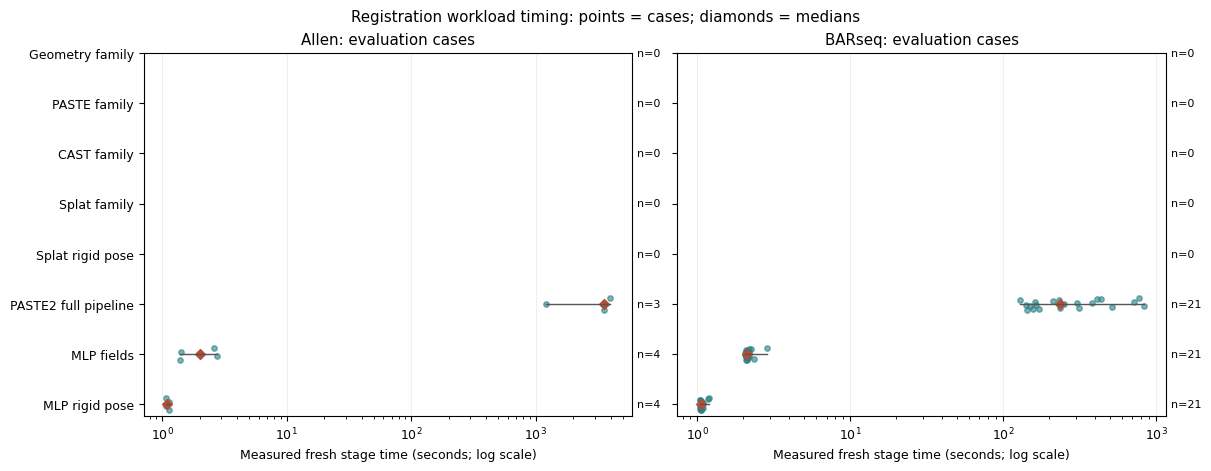

In [9]:
timings = timing_log.summary(cases).merge(
    inventory[['case','dataset','task','role']], on='case', validate='many_to_one')
timings.to_csv(OUTPUT/'timing_summary.csv', index=False)
timing_groups = ['dataset','task','role','shared_fraction','stage']
timing_stats = timings.groupby(timing_groups).measured_fresh_minutes.agg(['count','median','min','max'])
timing_stats.to_csv(OUTPUT/'timing_statistics.csv')
display(timing_stats)
events_path = OUTPUT/'timing_events.jsonl'
events = [json.loads(line) for line in events_path.read_text().splitlines()] if events_path.exists() else []
hardware = {json.dumps(event['hardware'], sort_keys=True) for event in events}
print('Recorded hardware configurations:', len(hardware))
for item in sorted(hardware):
    print(json.loads(item))
if len(hardware)>1:
    print('Multiple hardware configurations: stratify timing before making speed claims.')
evaluation_times = timings.loc[timings.role=='evaluation', 'measured_fresh_minutes']
if evaluation_times.notna().any():
    runtime = runtime_figure(timings, role='evaluation')
    for extension in ('pdf','png'):
        runtime.savefig(FIGURES/f'registration_runtime_stages.{extension}', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(runtime)
else:
    print('No measured fresh evaluation fit times. Cached fits have unknown historical timings.')


## Optional expression-score supplement

This retains the wider layout with coverage-weighted cosine, separately from the main figure.


In [10]:
MAKE_EXPRESSION_SUPPLEMENT = False
if MAKE_EXPRESSION_SUPPLEMENT:
    if not complete:
        raise RuntimeError('Complete the method matrix first.')
    supplement = publication_figure(cases, fitted, scores, methods=METHODS,
        example_method='Splat rigid', include_cosine=True, measurement_links=True, maximum_links=60)
    for extension in ('pdf','png'):
        supplement.savefig(FIGURES/f'registration_expression_supplement.{extension}', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(supplement)


## Reproduction and interpretation

This notebook does not select model settings from evaluation performance. Confirm completeness and inspect failure/overlap diagnostics before claiming improvements. Development and evaluation results must not be pooled as independent biological replicates.

To reproduce from a clean checkout, install the listed dependencies, configure the data directory, run the two download helpers, and run this notebook. There is no requirement to run a controls, benchmark, or previous publication notebook. Private model caches and imported copies can be deleted without affecting another notebook's fits.

See `docs/registration_publication_controls.md` for protocol details, artifact locations, timing limitations, and the commit manifest.
